# 03_1. 같은 분 거래 누락 분석 — **Reinvestment 제외판**

`03_same_minute_analysis.ipynb` 와 같은 계산을 `payment_format = Reinvestment` 거래를 **처음부터 빼고** 돌린다.
월말·월초에 한 계좌가 Reinvestment 를 분당 수백 건 쏘는 허브가 03 의 수치를 얼마나 끌어올렸는지 03 결과와 나란히 비교하려는 것.
결과 파일은 `_noReinvestment` 접미사로 저장되어 03 의 결과(`same_minute.json`, `same_minute_0*.png`)와 섞이지 않는다.
03 과 다른 부분은 **0. 설정의 `EXCLUDE_FORMATS`** 와 **1절의 포맷 분포·필터**, 2절 끝의 허브 포맷 확인뿐이다.

---

# 03. 같은 분(minute) 사각 분석 — "같은 분 2건 이상" 비율

v10 엣지 시간 피처는 `RANGE … AND INTERVAL '1 minute' PRECEDING` 창을 써서 **같은 분에 일어난 다른 거래를 전부 제외**한다
(`*_prior`, `*_last`→gap, `*_hour`). 원본 `ts` 가 분 단위라 같은 분 안의 순서를 모르기 때문인데,
그 대신 "같은 분에 같은 쌍/송신자/수신자로 몇 건이 더 있었는가"라는 정보가 어떤 피처에도 들어가지 않는다.

이 노트북은 01 의 `transactions.parquet` (+ `patterns.parquet`, 있으면 02 의 `edge_features.parquet`)로
그 사각이 **라벨1(세탁)에서 얼마나 큰지**를 재서, `same_minute_count` 류 피처를 추가할지 / `EXCLUDE` 를 바꿀지 판단할 근거를 만든다.

| 절 | 보는 것 | 입력 |
|---|---|---|
| 3 | 라벨별 "같은 분 2건 이상" 비율, lift, 재현율 (쌍/송신/수신 3개 파티션) | transactions |
| 4 | 같은 분 다른 거래 수(siblings) 분포 — 라벨별 | transactions |
| 5 | 패턴 유형별 비율 + 시도(attempt) 안에서 같은 분에 몰린 정도 | patterns |
| 6 | 현재 피처의 사각: siblings>0 인데 `*_prior=0`(첫 거래로 보임) / `*_hour=0` 비율, 1h 건수 과소 추정 | edge_features (선택) |
| 7 | 직전 거래까지 gap 분포 — gap=0(같은 분)에 얼마나 몰리는가 | transactions (선택, 윈도우 3개) |

용어: **siblings** = 같은 파티션 키·같은 분의 *다른* 거래 수 (`count(*) OVER (PARTITION BY key, ts) - 1`).
`EXCLUDE='0 second'` 로 바꿨을 때 `*_hour` 에 더해지는 양이 정확히 이 값이다 (자기 자신 1 제외).

그림 라벨은 GPU 컨테이너에 한글 폰트가 없어 영어로 둔다. 결과는 `parquets/<DATASET>/analysis/` 에 json + png 로 남긴다.

## 0. 설정

In [1]:
!pip install --break-system-packages --no-cache-dir -q duckdb pyarrow matplotlib

In [2]:
from pathlib import Path
import json, time
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt

DATASET = "HI-Large"
DAY_FROM, DAY_TO = None, None        # 예: "2022-09-01", "2022-09-14". None 이면 전체 기간 (Large 전체는 GROUP BY 3번 + 윈도우라 수십 분)
EXCLUDE_FORMATS = ["Reinvestment"]  # 03 과의 유일한 차이: 이 payment_format 을 tx 에서 뺀다. [] 이면 03 과 동일
FEATURES_DIR = "features"            # 02 출력 폴더명 (features / features_<tag>). 없으면 6절은 건너뜀
NORMAL_SAMPLE = 2_000_000            # 6절에서 라벨0 거래를 이만큼만 표본 추출 (라벨1 은 전부)
RUN_GAP = True                       # 7절 (lag 윈도우 3개). 시간 아끼려면 False
TAG = "noReinvestment"               # 결과 파일 접미사 — 03 의 결과와 구분
THREADS, MEMORY, WORK_DIR = 4, "6GB", None   # Large 는 8 / "24GB" 이상 권장

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "datasets").is_dir())   # 저장소 루트
BASE = ROOT / "parquets" / DATASET
OUT = BASE / "analysis"; OUT.mkdir(parents=True, exist_ok=True)
FEAT = BASE / FEATURES_DIR / "edge_features.parquet"
assert (BASE / "transactions.parquet").is_file(), "01 먼저 실행"
q = lambda v: "'" + str(v).replace("'", "''") + "'"
suffix = f"_{TAG}" if TAG else ""
fig_path = lambda name: OUT / f"same_minute_{name}{suffix}.png"

work = (Path(WORK_DIR) if WORK_DIR else OUT) / "work_same_minute.duckdb"
for stale in (work, Path(str(work) + ".wal")): stale.unlink(missing_ok=True)
con = duckdb.connect(str(work))
con.execute(f"SET threads={THREADS}"); con.execute(f"SET memory_limit='{MEMORY}'"); con.execute("SET preserve_insertion_order=false")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
C_NORMAL, C_LAUND = "#8da0cb", "#e15759"
PARTS = {"pair": "src, dst", "sender": "src", "receiver": "dst"}     # 02 temporal 과 같은 세 파티션
result = dict(dataset=DATASET, day_from=DAY_FROM, day_to=DAY_TO, exclude_formats=EXCLUDE_FORMATS, features_dir=FEATURES_DIR)
print(ROOT, "\n", OUT, f"\n제외 포맷: {EXCLUDE_FORMATS}  접미사: {suffix}", "\n02 피처:", FEAT if FEAT.is_file() else "없음 (6절 건너뜀)")

/workspace/money_laundry_ai_ 
 /workspace/money_laundry_ai_/parquets/HI-Large/analysis 
제외 포맷: ['Reinvestment']  접미사: _noReinvestment 
02 피처: /workspace/money_laundry_ai_/parquets/HI-Large/features/edge_features.parquet


## 1. 입력 `tx`

02 와 같은 필터: 중복 대표만(`duplicate_group_id IS NULL OR edge_id = duplicate_group_id`). 날짜 범위를 주면 그 안만.
필요한 열만 올린다 (`edge_id, ts, src, dst, is_laundering, day`).

**03 과 다른 점**: 먼저 포맷별 건수·세탁률을 찍어 무엇을 빼는지 확인한 뒤, `EXCLUDE_FORMATS` 를 `tx` 에서 제외한다 → 2절 이후 전부 그 기준.
(6절에서 붙이는 02 피처값 `*_prior/*_hour` 는 02 가 전체 포맷으로 계산한 값이라 그대로다 — 즉 6절은 "Reinvestment 를 뺀 거래들에 대해 현재 피처가 어떻게 보이나".)

In [3]:
where = ["(duplicate_group_id IS NULL OR edge_id = duplicate_group_id)"]
if DAY_FROM: where.append(f"day >= DATE {q(DAY_FROM)}")
if DAY_TO:   where.append(f"day <= DATE {q(DAY_TO)}")
# 포맷별 건수·세탁률 (필터 전) — 무엇을 얼마나 빼는지
fmt = con.execute(f"""
    SELECT payment_format, count(*) AS tx, sum(is_laundering::INT) AS laundering,
           count(*) / sum(count(*)) OVER () AS share, sum(is_laundering::INT) / count(*) AS laundering_rate
    FROM read_parquet({q(BASE/'transactions.parquet')}) WHERE {' AND '.join(where)} GROUP BY 1 ORDER BY tx DESC""").df().set_index("payment_format")
fmt["excluded"] = fmt.index.isin(EXCLUDE_FORMATS)
result["format_breakdown"] = fmt.round(6).to_dict("index")
display(fmt.style.format({"tx": "{:,}", "laundering": "{:,}", "share": "{:.2%}", "laundering_rate": "{:.4%}"}).set_caption("payment_format breakdown (before exclusion)"))

if EXCLUDE_FORMATS: where.append("payment_format NOT IN (" + ", ".join(q(f) for f in EXCLUDE_FORMATS) + ")")
t0 = time.perf_counter()
con.execute(f"""
    CREATE OR REPLACE TABLE tx AS
    SELECT edge_id, ts, src, dst, is_laundering, day, payment_format
    FROM read_parquet({q(BASE/'transactions.parquet')})
    WHERE {' AND '.join(where)}""")
n, n_l, d0, d1 = con.execute("SELECT count(*), sum(is_laundering::INT), min(day), max(day) FROM tx").fetchone()
result.update(rows=n, laundering=n_l, base_rate=n_l / n, day_min=str(d0), day_max=str(d1))
print(f"거래 {n:,}  라벨1 {n_l:,} ({n_l/n:.4%})  기간 {d0} ~ {d1}   ({time.perf_counter()-t0:.0f}s)")
if EXCLUDE_FORMATS:
    ex = fmt[fmt.excluded]
    print(f"제외: {int(ex.tx.sum()):,} 건 (라벨1 {int(ex.laundering.sum()):,})  ← {', '.join(ex.index)}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,tx,laundering,share,laundering_rate,excluded
payment_format,,,,,
Cheque,"70,586,103","13,260.0",39.28%,0.0188%,False
Credit Card,"50,856,118","7,846.0",28.30%,0.0154%,False
ACH,"22,126,171","199,164.0",12.31%,0.9001%,False
Cash,"18,412,981","3,663.0",10.25%,0.0199%,False
Reinvestment,"7,410,555",0.0,4.12%,0.0000%,True
Wire,"6,405,231",5.0,3.56%,0.0001%,False
Bitcoin,"3,904,920","1,608.0",2.17%,0.0412%,False


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

거래 172,291,524  라벨1 225,546 (0.1309%)  기간 2022-08-01 ~ 2023-01-12   (20s)
제외: 7,410,555 건 (라벨1 0)  ← Reinvestment


## 2. 같은 분 그룹 집계 `grp_<partition>`

`(키, ts)` 로 GROUP BY 해서 그룹 크기 `n` 과 그 안의 라벨1 수 `n_l` 만 남긴다.
행 단위로 다시 붙이지 않아도 3·4절 지표는 이 표만으로 계산된다 (라벨1 거래 수 = `sum(n_l)`, siblings = `n-1`).
Large 는 그룹이 거의 거래 수만큼 나오니(대부분 1건) 메모리 스필을 각오한다.

In [4]:
for name, key in PARTS.items():
    t0 = time.perf_counter()
    con.execute(f"""
        CREATE OR REPLACE TABLE grp_{name} AS
        SELECT {key}, ts, count(*) AS n, sum(is_laundering::INT) AS n_l FROM tx GROUP BY {key}, ts""")
    g, multi, biggest = con.execute(f"SELECT count(*), count(*) FILTER (WHERE n >= 2), max(n) FROM grp_{name}").fetchone()
    print(f"{name:9s} 그룹 {g:>13,}  2건 이상 그룹 {multi:>11,}  최대 {biggest:,}건/분   ({time.perf_counter()-t0:.0f}s)")
# 가장 큰 '같은 분' 덩어리 — 어떤 상황인지 눈으로 확인 (src=송신 계좌 node_id, n=그 분에 보낸 건수, n_l=그중 세탁)
display(con.execute("SELECT src, ts, n, n_l FROM grp_sender ORDER BY n DESC LIMIT 5").df())
# Reinvestment 를 뺀 뒤에도 남는 허브의 포맷 구성 (가장 몰린 송신자-분 상위 50개)
con.execute("""SELECT t.payment_format, count(*) AS tx, count(DISTINCT t.src) AS senders, min(t.day) AS day_min, max(t.day) AS day_max
               FROM tx t JOIN (SELECT src, ts FROM grp_sender ORDER BY n DESC LIMIT 50) g USING (src, ts)
               GROUP BY 1 ORDER BY tx DESC""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

pair      그룹   168,523,310  2건 이상 그룹   3,726,486  최대 5건/분   (24s)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

sender    그룹   150,756,608  2건 이상 그룹   7,859,363  최대 653건/분   (20s)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

receiver  그룹   167,561,421  2건 이상 그룹   4,397,780  최대 11건/분   (22s)


,src,ts,n,n_l
0,47308,2022-09-30 00:02:00,653,0.0
1,47308,2022-09-30 00:06:00,644,1.0
2,47308,2022-09-30 00:04:00,639,0.0
3,47308,2022-09-30 00:12:00,634,3.0
4,47308,2022-09-30 00:23:00,625,1.0


,payment_format,tx,senders,day_min,day_max
0,Cheque,13590,1,2022-08-31,2022-09-30
1,Credit Card,8547,1,2022-08-31,2022-09-30
2,Cash,7891,1,2022-08-31,2022-09-30


## 3. 라벨별 "같은 분 2건 이상" 비율

거래 단위 비율. 파티션별로
- `rate_normal` / `rate_laundering` : 그 라벨 거래 중 같은 분에 다른 거래가 1건 이상 있는 비율 (`n ≥ 2`)
- `precision` : 같은 분 2건 이상인 거래 중 라벨1 비율 = P(세탁 | siblings>0)
- `lift` : precision / 전체 라벨1 비율. 1 이면 정보 없음
- `recall` : 라벨1 중 siblings>0 인 비율 (= rate_laundering) — 이 비율만큼의 세탁 거래가 현재 피처에서 "같은 분 정보 없음"으로 들어간다

In [5]:
rows = []
for name in PARTS:
    tx_all, all_multi, tx_l, l_multi = con.execute(f"""
        SELECT sum(n), coalesce(sum(n) FILTER (WHERE n >= 2), 0), sum(n_l), coalesce(sum(n_l) FILTER (WHERE n >= 2), 0) FROM grp_{name}""").fetchone()
    tx_n, n_multi = tx_all - tx_l, all_multi - l_multi
    rows.append(dict(partition=name, tx_normal_multi=int(n_multi), tx_laundering_multi=int(l_multi),
                     rate_normal=n_multi / tx_n, rate_laundering=l_multi / tx_l,
                     precision=l_multi / all_multi if all_multi else float("nan"),
                     lift=(l_multi / all_multi) / (tx_l / tx_all) if all_multi else float("nan"),
                     recall=l_multi / tx_l))
rates = pd.DataFrame(rows).set_index("partition")
result["same_minute_rate"] = rates.round(6).to_dict("index")
rates.style.format({"tx_normal_multi": "{:,}", "tx_laundering_multi": "{:,}", "rate_normal": "{:.2%}", "rate_laundering": "{:.2%}",
                    "precision": "{:.3%}", "lift": "{:.2f}", "recall": "{:.2%}"})

,tx_normal_multi,tx_laundering_multi,rate_normal,rate_laundering,precision,lift,recall
partition,,,,,,,
pair,"7,476,459","18,241",4.35%,8.09%,0.243%,1.86,8.09%
sender,"29,282,342","111,937",17.02%,49.63%,0.381%,2.91,49.63%
receiver,"9,103,066","24,817",5.29%,11.00%,0.272%,2.08,11.00%


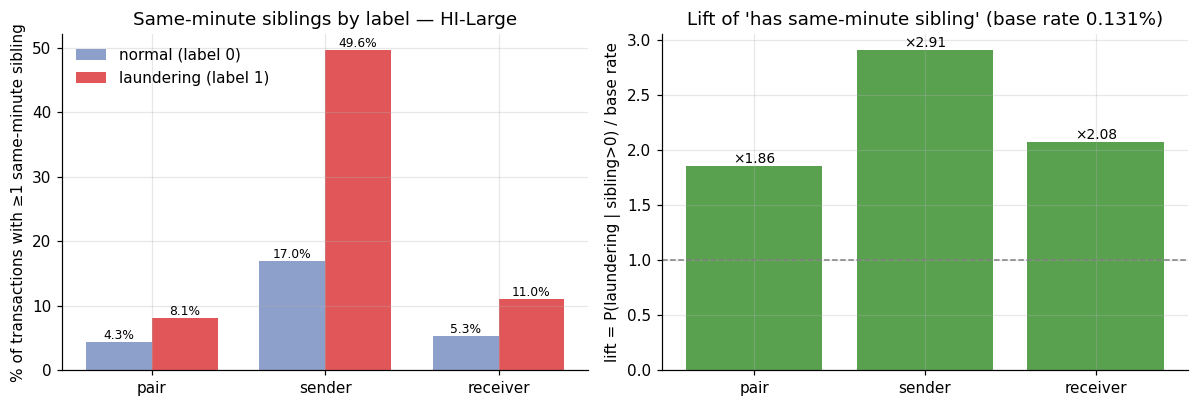

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(rates)); w = 0.38
ax = axes[0]
ax.bar(x - w/2, rates.rate_normal * 100, w, color=C_NORMAL, label="normal (label 0)")
ax.bar(x + w/2, rates.rate_laundering * 100, w, color=C_LAUND, label="laundering (label 1)")
for i, (a, b) in enumerate(zip(rates.rate_normal, rates.rate_laundering)):
    ax.text(i - w/2, a*100, f"{a:.1%}", ha="center", va="bottom", fontsize=8); ax.text(i + w/2, b*100, f"{b:.1%}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(rates.index); ax.set_ylabel("% of transactions with ≥1 same-minute sibling")
ax.set_title(f"Same-minute siblings by label — {DATASET}"); ax.legend(frameon=False)
ax = axes[1]
ax.bar(x, rates.lift, color="#59a14f"); ax.axhline(1, color="gray", ls="--", lw=1)
for i, v in enumerate(rates.lift): ax.text(i, v, f"×{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(rates.index); ax.set_ylabel("lift = P(laundering | sibling>0) / base rate")
ax.set_title(f"Lift of 'has same-minute sibling' (base rate {result['base_rate']:.3%})")
fig.tight_layout(); fig.savefig(fig_path("01_rate"), bbox_inches="tight"); plt.show()

## 4. siblings 수 분포 — 라벨별

`siblings = n − 1` 을 버킷으로 묶어 라벨 안에서의 비율을 본다. 라벨1 이 `2-4`, `5-9` 쪽에 몰리면 FAN-OUT/FAN-IN 류가 같은 분에 찍힌다는 뜻.
오른쪽 꼬리가 중요하니 y 는 로그 눈금.

In [7]:
BUCKETS = ["0", "1", "2-4", "5-9", "10-49", "50+"]
bucket_sql = "CASE WHEN n-1 = 0 THEN '0' WHEN n-1 = 1 THEN '1' WHEN n-1 <= 4 THEN '2-4' WHEN n-1 <= 9 THEN '5-9' WHEN n-1 <= 49 THEN '10-49' ELSE '50+' END"
dist = {}
for name in PARTS:
    d = con.execute(f"SELECT {bucket_sql} AS siblings, sum(n) - sum(n_l) AS normal, sum(n_l) AS laundering FROM grp_{name} GROUP BY 1").df()
    d = d.set_index("siblings").reindex(BUCKETS).fillna(0).astype("int64")
    dist[name] = d
result["siblings_distribution"] = {k: v.to_dict() for k, v in dist.items()}
pd.concat({k: (v / v.sum()) for k, v in dist.items()}, axis=1).style.format("{:.3%}")

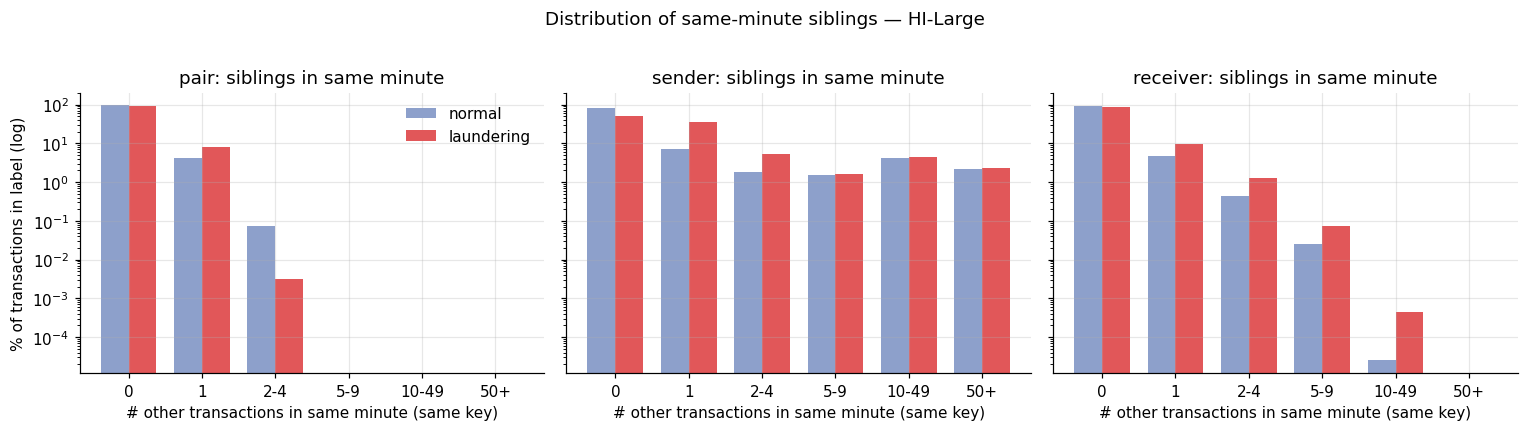

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
x = np.arange(len(BUCKETS)); w = 0.38
for ax, (name, d) in zip(axes, dist.items()):
    share = d / d.sum()
    ax.bar(x - w/2, share.normal * 100, w, color=C_NORMAL, label="normal")
    ax.bar(x + w/2, share.laundering * 100, w, color=C_LAUND, label="laundering")
    ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(BUCKETS); ax.set_title(f"{name}: siblings in same minute")
    ax.set_xlabel("# other transactions in same minute (same key)")
axes[0].set_ylabel("% of transactions in label (log)"); axes[0].legend(frameon=False)
fig.suptitle(f"Distribution of same-minute siblings — {DATASET}", y=1.02)
fig.tight_layout(); fig.savefig(fig_path("02_distribution"), bbox_inches="tight"); plt.show()

## 5. 패턴 유형별

`patterns.parquet` 로 라벨1 중 패턴 파일에 매칭된 거래(`edge_id` 있음)만 보고, 유형별로
- `rate_<partition>` : 그 유형 거래 중 siblings>0 비율 (3절과 같은 정의, 파티션 상대는 패턴 밖 거래도 포함)
- `attempt_compactness` : 시도(attempt) 안에서 `1 − 서로 다른 분 수 / 거래 수` 의 평균. 1 에 가까우면 시도 전체가 거의 한 분에 찍힘, 0 이면 전부 다른 분

매칭 안 된 라벨1(unmatched) 은 패턴 없이 `UNMATCHED` 로 한 줄 더 둔다.

In [9]:
PAT = BASE / "patterns.parquet"
if PAT.is_file():
    con.execute(f"""
        CREATE OR REPLACE TABLE lab AS
        SELECT t.edge_id, t.ts, t.src, t.dst, coalesce(p.pattern_type, 'UNMATCHED') AS pattern_type, p.attempt_id
        FROM tx t LEFT JOIN (SELECT edge_id, pattern_type, attempt_id FROM read_parquet({q(PAT)}) WHERE edge_id IS NOT NULL) p USING (edge_id)
        WHERE t.is_laundering""")
    con.execute("""
        CREATE OR REPLACE TABLE lab_sib AS
        SELECT l.*, gp.n - 1 AS sib_pair, gs.n - 1 AS sib_sender, gr.n - 1 AS sib_receiver
        FROM lab l
        JOIN grp_pair gp ON gp.src = l.src AND gp.dst = l.dst AND gp.ts = l.ts
        JOIN grp_sender gs ON gs.src = l.src AND gs.ts = l.ts
        JOIN grp_receiver gr ON gr.dst = l.dst AND gr.ts = l.ts""")
    by_pattern = con.execute("""
        WITH compact AS (SELECT attempt_id, pattern_type, 1.0 - count(DISTINCT ts)::DOUBLE / count(*) AS c
                         FROM lab WHERE attempt_id IS NOT NULL GROUP BY 1, 2)
        SELECT s.pattern_type, count(*) AS tx, count(DISTINCT s.attempt_id) AS attempts,
               avg((sib_pair > 0)::INT) AS rate_pair, avg((sib_sender > 0)::INT) AS rate_sender, avg((sib_receiver > 0)::INT) AS rate_receiver,
               avg(sib_sender) AS mean_sib_sender, avg(sib_receiver) AS mean_sib_receiver,
               (SELECT avg(c) FROM compact c WHERE c.pattern_type = s.pattern_type) AS attempt_compactness
        FROM lab_sib s GROUP BY 1 ORDER BY tx DESC""").df().set_index("pattern_type")
    result["by_pattern"] = by_pattern.round(6).to_dict("index")
    display(by_pattern.style.format({"tx": "{:,}", "attempts": "{:,}", "rate_pair": "{:.1%}", "rate_sender": "{:.1%}", "rate_receiver": "{:.1%}",
                                     "mean_sib_sender": "{:.2f}", "mean_sib_receiver": "{:.2f}", "attempt_compactness": "{:.3f}"}, na_rep="-"))
else:
    by_pattern = None; print("patterns.parquet 없음 — 5절 건너뜀")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,tx,attempts,rate_pair,rate_sender,rate_receiver,mean_sib_sender,mean_sib_receiver,attempt_compactness
pattern_type,,,,,,,,
UNMATCHED,"87,610",0,6.6%,32.9%,14.0%,8.16,0.20,-
SCATTER-GATHER,"26,978","2,067",11.3%,60.4%,11.3%,0.68,0.11,0.000
GATHER-SCATTER,"26,361","2,054",3.0%,57.0%,3.1%,0.59,0.03,0.000
STACK,"23,624","2,096",13.1%,64.2%,13.2%,0.73,0.13,0.000
FAN-OUT,"13,554","2,040",0.8%,58.1%,0.9%,0.59,0.01,0.000
FAN-IN,"13,287","2,014",3.1%,58.3%,3.2%,0.60,0.03,0.000
CYCLE,"12,340","2,086",20.6%,61.6%,20.6%,0.75,0.21,0.000
BIPARTITE,"12,174","2,109",3.4%,60.2%,3.5%,0.62,0.03,0.000
RANDOM,"9,618","2,001",21.3%,63.1%,21.3%,0.77,0.21,0.000


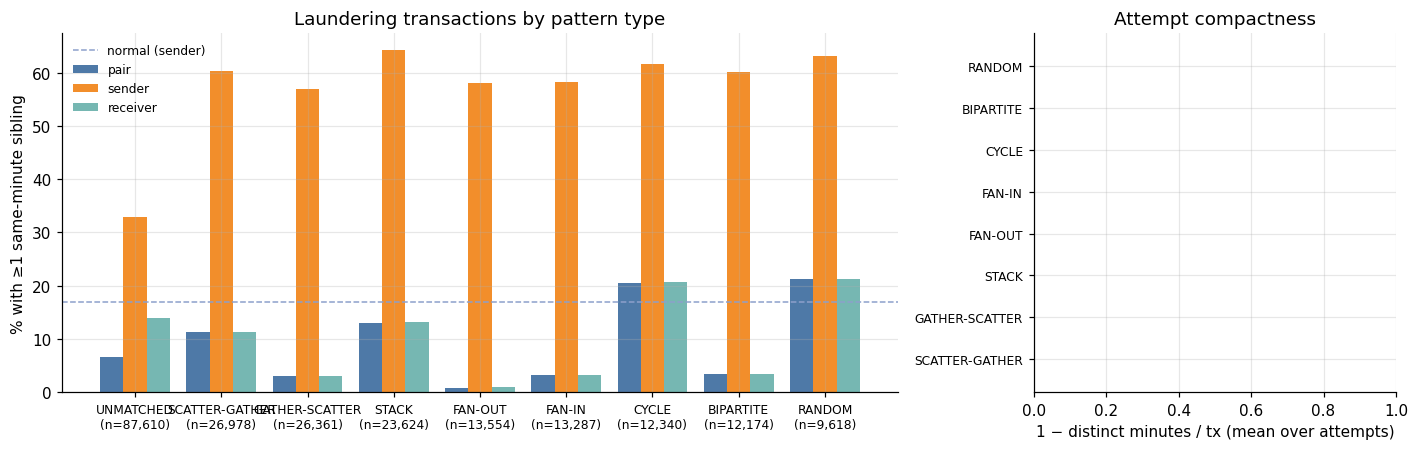

In [10]:
if by_pattern is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1.3]})
    bp = by_pattern.sort_values("tx", ascending=False)
    x = np.arange(len(bp)); w = 0.27
    ax = axes[0]
    for i, (col, c) in enumerate([("rate_pair", "#4e79a7"), ("rate_sender", "#f28e2b"), ("rate_receiver", "#76b7b2")]):
        ax.bar(x + (i-1)*w, bp[col] * 100, w, color=c, label=col.replace("rate_", ""))
    ax.axhline(rates.loc["sender", "rate_normal"] * 100, color=C_NORMAL, ls="--", lw=1, label="normal (sender)")
    ax.set_xticks(x); ax.set_xticklabels([f"{p}\n(n={n:,})" for p, n in zip(bp.index, bp.tx)], fontsize=8)
    ax.set_ylabel("% with ≥1 same-minute sibling"); ax.set_title("Laundering transactions by pattern type"); ax.legend(frameon=False, fontsize=8)
    ax = axes[1]
    cmp_ = bp.attempt_compactness.dropna()
    ax.barh(np.arange(len(cmp_)), cmp_.values, color="#b07aa1"); ax.set_yticks(np.arange(len(cmp_))); ax.set_yticklabels(cmp_.index, fontsize=8)
    ax.set_xlim(0, 1); ax.set_xlabel("1 − distinct minutes / tx (mean over attempts)"); ax.set_title("Attempt compactness")
    fig.tight_layout(); fig.savefig(fig_path("03_pattern"), bbox_inches="tight"); plt.show()

## 6. 현재 피처의 사각 (02 `edge_features.parquet` 필요)

02 가 저장한 원시 창 값(`pair_prior, pair_hour, sender_*, receiver_*`)에 siblings 를 붙여서,
- `blind_prior` : siblings>0 **이면서** `*_prior = 0` → 같은 분에 상대가 있는데 피처는 "이 키의 첫 거래"(gap 0, prior 0)로 본다
- `blind_hour`  : siblings>0 이면서 `*_hour = 0` → 1시간 창이 비어 보이지만 실제로는 같은 분에 거래가 있었다
- `hour_undercount` : `EXCLUDE='0 second'` 였다면 `*_hour` 가 커지는 비율 = mean(siblings) / mean(hour + siblings)

라벨1 은 전부, 라벨0 은 `NORMAL_SAMPLE` 건 표본. 02 를 `CONTEXT_END`/`WINDOW_DAYS` 로 잘라 돌렸으면 교집합만 들어간다.

In [11]:
if FEAT.is_file():
    t0 = time.perf_counter()
    p_sample = min(1.0, NORMAL_SAMPLE / max(result["rows"] - result["laundering"], 1))
    con.execute(f"""
        CREATE OR REPLACE TABLE smp AS
        SELECT t.edge_id, t.ts, t.src, t.dst, t.is_laundering,
               gp.n - 1 AS sib_pair, gs.n - 1 AS sib_sender, gr.n - 1 AS sib_receiver
        FROM (SELECT * FROM tx WHERE is_laundering OR random() < {p_sample}) t
        JOIN grp_pair gp ON gp.src = t.src AND gp.dst = t.dst AND gp.ts = t.ts
        JOIN grp_sender gs ON gs.src = t.src AND gs.ts = t.ts
        JOIN grp_receiver gr ON gr.dst = t.dst AND gr.ts = t.ts""")
    con.execute(f"""
        CREATE OR REPLACE TABLE smp_feat AS
        SELECT s.*, f.pair_prior, f.pair_hour, f.sender_prior, f.sender_hour, f.receiver_prior, f.receiver_hour
        FROM smp s JOIN read_parquet({q(FEAT)}) f USING (edge_id)""")
    cols = []
    for name in PARTS:
        cols += [f"avg((sib_{name} > 0 AND {name}_prior = 0)::INT) AS blind_prior_{name}",
                 f"avg((sib_{name} > 0 AND {name}_hour  = 0)::INT) AS blind_hour_{name}",
                 f"avg(sib_{name}) / nullif(avg({name}_hour + sib_{name}), 0) AS hour_undercount_{name}",
                 f"avg({name}_hour) AS hour_excl_{name}", f"avg({name}_hour + sib_{name}) AS hour_incl_{name}"]
    blind = con.execute("SELECT is_laundering, count(*) AS rows, " + ", ".join(cols) + " FROM smp_feat GROUP BY 1 ORDER BY 1").df().set_index("is_laundering")
    blind.index = blind.index.map({False: "normal", True: "laundering"})
    result["blind_spot"] = blind.round(6).to_dict("index"); result["normal_sample_p"] = p_sample
    print(f"표본 {int(blind.rows.sum()):,} 행 (라벨0 추출률 {p_sample:.4f})   ({time.perf_counter()-t0:.0f}s)")
    display(blind.T.style.format("{:.4f}"))
else:
    blind = None; print("edge_features.parquet 없음 — 02 먼저 실행하면 6절을 볼 수 있다")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

표본 2,224,918 행 (라벨0 추출률 0.0116)   (30s)


is_laundering,normal,laundering
rows,1999372.0000,225546.0000
blind_prior_pair,0.0006,0.0651
blind_hour_pair,0.0283,0.0798
hour_undercount_pair,0.0648,0.5594
hour_excl_pair,0.6405,0.0637
hour_incl_pair,0.6848,0.1446
blind_prior_sender,0.0002,0.0038
blind_hour_sender,0.0380,0.3757
hour_undercount_sender,0.0175,0.0193
hour_excl_sender,167.9839,181.1614


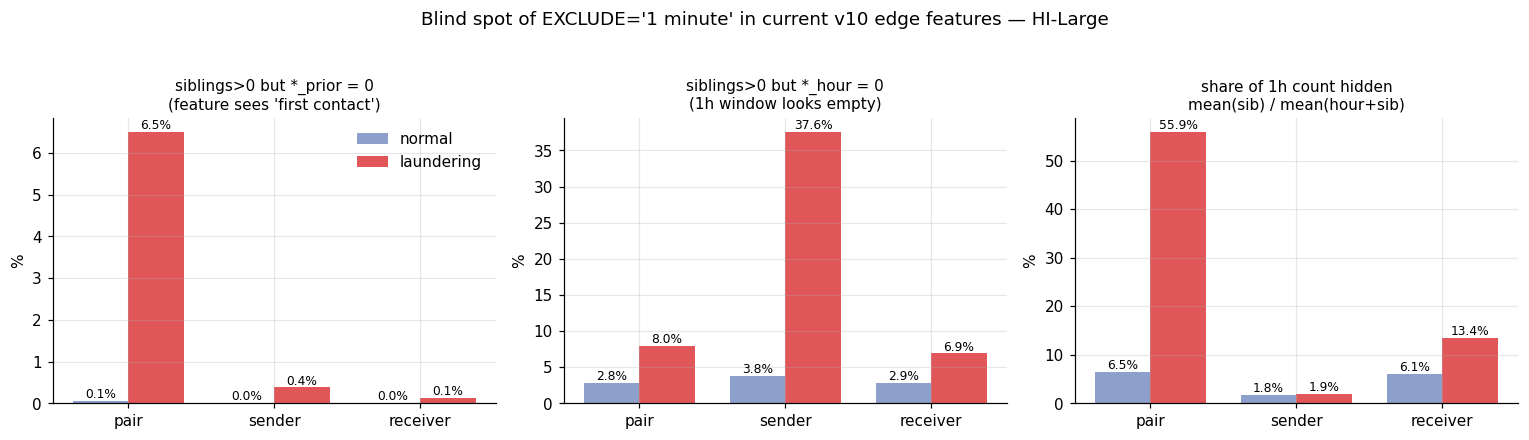

In [12]:
if blind is not None:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    x = np.arange(len(PARTS)); w = 0.38
    for ax, metric, title in zip(axes, ["blind_prior", "blind_hour", "hour_undercount"],
                                 ["siblings>0 but *_prior = 0\n(feature sees 'first contact')", "siblings>0 but *_hour = 0\n(1h window looks empty)",
                                  "share of 1h count hidden\nmean(sib) / mean(hour+sib)"]):
        v0 = [blind.loc["normal", f"{metric}_{p}"] for p in PARTS]; v1 = [blind.loc["laundering", f"{metric}_{p}"] for p in PARTS]
        ax.bar(x - w/2, np.array(v0) * 100, w, color=C_NORMAL, label="normal"); ax.bar(x + w/2, np.array(v1) * 100, w, color=C_LAUND, label="laundering")
        for i, (a, b) in enumerate(zip(v0, v1)):
            ax.text(i - w/2, a*100, f"{a:.1%}", ha="center", va="bottom", fontsize=8); ax.text(i + w/2, b*100, f"{b:.1%}", ha="center", va="bottom", fontsize=8)
        ax.set_xticks(x); ax.set_xticklabels(list(PARTS)); ax.set_title(title, fontsize=10); ax.set_ylabel("%")
    axes[0].legend(frameon=False)
    fig.suptitle(f"Blind spot of EXCLUDE='1 minute' in current v10 edge features — {DATASET}", y=1.04)
    fig.tight_layout(); fig.savefig(fig_path("04_blind_spot"), bbox_inches="tight"); plt.show()

## 7. 직전 거래까지 gap 분포 (선택)

`lag(ts) OVER (PARTITION BY 키 ORDER BY ts)` 로 **같은 분을 포함한** 진짜 직전 거래까지의 분 차이를 구한다.
gap=0 이 같은 분. 현재 피처의 `*_gap_minutes` 는 이 gap=0 행을 "같은 분을 건너뛴 그 이전 거래"까지의 gap 으로 바꿔 놓거나, 없으면 0 (첫 거래와 구분 불가) 으로 넣는다.
`share_gap0_among_has_prev` = 직전 거래가 있는 행 중 gap=0 비율 — 시간 피처가 쓰는 "직전" 정보 중 얼마가 같은 분에 있는지.

In [13]:
GAP_BUCKETS = ["none", "0", "1", "2-5", "6-60", "61-1440", "1441+"]
gap_bucket = lambda g: (f"CASE WHEN {g} IS NULL THEN 'none' WHEN {g} = 0 THEN '0' WHEN {g} = 1 THEN '1' WHEN {g} <= 5 THEN '2-5' "
                        f"WHEN {g} <= 60 THEN '6-60' WHEN {g} <= 1440 THEN '61-1440' ELSE '1441+' END")
if RUN_GAP:
    t0 = time.perf_counter()
    lags = ", ".join(f"date_diff('minute', lag(ts) OVER (PARTITION BY {key} ORDER BY ts), ts) AS gap_{name}" for name, key in PARTS.items())
    con.execute(f"CREATE OR REPLACE TABLE gaps AS SELECT is_laundering, {lags} FROM tx")
    print(f"윈도우 {time.perf_counter()-t0:.0f}s")
    gap_dist, gap_summary = {}, {}
    for name in PARTS:
        d = con.execute(f"SELECT {gap_bucket(f'gap_{name}')} AS gap, count(*) FILTER (WHERE NOT is_laundering) AS normal, count(*) FILTER (WHERE is_laundering) AS laundering FROM gaps GROUP BY 1").df()
        gap_dist[name] = d.set_index("gap").reindex(GAP_BUCKETS).fillna(0).astype("int64")
        has_prev = gap_dist[name].drop("none"); gap_summary[name] = (has_prev.loc["0"] / has_prev.sum()).to_dict()
    result["gap_distribution"] = {k: v.to_dict() for k, v in gap_dist.items()}; result["share_gap0_among_has_prev"] = gap_summary
    display(pd.DataFrame(gap_summary).T.style.format("{:.2%}").set_caption("share of gap=0 among rows that have a previous transaction"))
    display(pd.concat({k: v / v.sum() for k, v in gap_dist.items()}, axis=1).style.format("{:.3%}"))
else:
    gap_dist = None; print("RUN_GAP=False — 7절 건너뜀")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

윈도우 61s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,normal,laundering
pair,2.28%,12.14%
sender,12.60%,31.83%
receiver,2.76%,6.40%


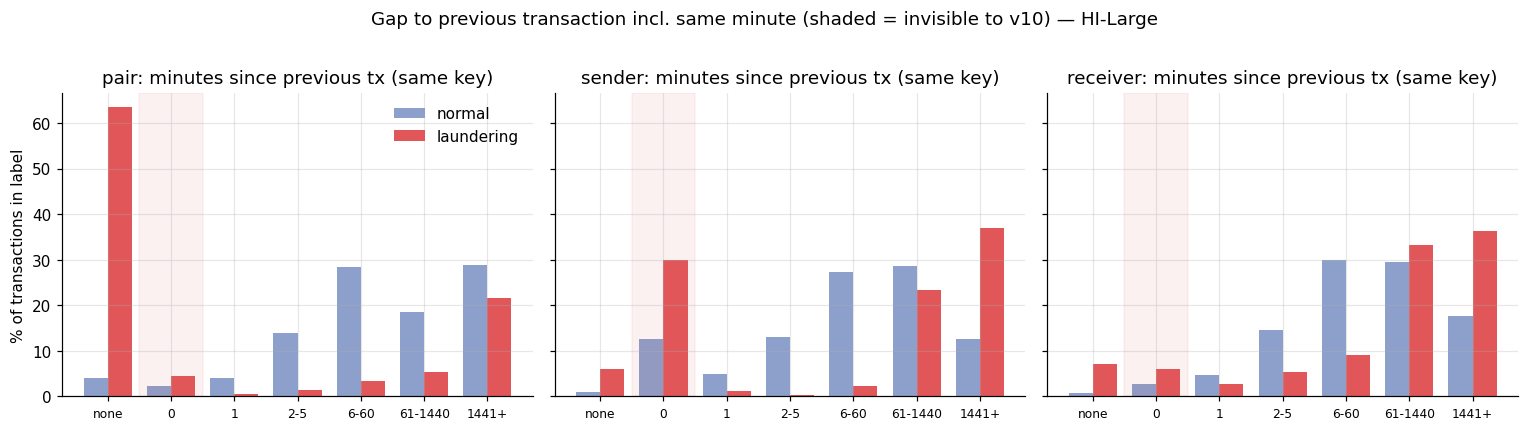

In [14]:
if gap_dist is not None:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
    x = np.arange(len(GAP_BUCKETS)); w = 0.38
    for ax, (name, d) in zip(axes, gap_dist.items()):
        share = d / d.sum()
        ax.bar(x - w/2, share.normal * 100, w, color=C_NORMAL, label="normal"); ax.bar(x + w/2, share.laundering * 100, w, color=C_LAUND, label="laundering")
        ax.set_xticks(x); ax.set_xticklabels(GAP_BUCKETS, fontsize=8); ax.set_title(f"{name}: minutes since previous tx (same key)")
        ax.axvspan(0.5, 1.5, color=C_LAUND, alpha=0.08)   # gap=0 = excluded by EXCLUDE='1 minute'
    axes[0].set_ylabel("% of transactions in label"); axes[0].legend(frameon=False)
    fig.suptitle(f"Gap to previous transaction incl. same minute (shaded = invisible to v10) — {DATASET}", y=1.02)
    fig.tight_layout(); fig.savefig(fig_path("05_gap"), bbox_inches="tight"); plt.show()

## 8. 마무리 — `analysis/same_minute<tag>.json`, 작업 파일 정리

In [15]:
con.close()
for stale in (work, Path(str(work) + ".wal")): stale.unlink(missing_ok=True)
out_json = OUT / f"same_minute{suffix}.json"
out_json.write_text(json.dumps(result, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(json.dumps({k: result[k] for k in ("dataset", "rows", "laundering", "base_rate", "day_min", "day_max")}, ensure_ascii=False, default=str))
print(pd.DataFrame(result["same_minute_rate"]).T[["rate_normal", "rate_laundering", "lift", "recall"]].round(4))
for f in sorted(OUT.glob("same_minute*.*")): print(f"{f.name:40s} {f.stat().st_size/1e3:8.1f} KB")

# 03(전체) 결과가 있으면 3절 지표를 나란히 — Δ = 이번(제외) − 03(전체)
base_json = OUT / "same_minute.json"
if base_json.is_file():
    base = json.loads(base_json.read_text(encoding="utf-8"))
    cols = ["rate_normal", "rate_laundering", "lift", "recall"]
    a = pd.DataFrame(base["same_minute_rate"]).T[cols].astype(float); b = pd.DataFrame(result["same_minute_rate"]).T[cols].astype(float)
    cmp_tbl = pd.concat({"all(03)": a, "excl(03_1)": b, "Δ": b - a}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)[cols]
    print(f"\n03 전체 기준 라벨1 {base['laundering']:,} / 기저율 {base['base_rate']:.4%}  →  제외 후 라벨1 {result['laundering']:,} / 기저율 {result['base_rate']:.4%}")
    display(cmp_tbl.round(4))
else:
    print("03 의 same_minute.json 이 없어 비교 표는 생략 (03 을 먼저 돌리면 여기 나란히 나온다)")

{"dataset": "HI-Large", "rows": 172291524, "laundering": 225546, "base_rate": 0.0013090951589702115, "day_min": "2022-08-01", "day_max": "2023-01-12"}
          rate_normal  rate_laundering    lift  recall
pair           0.0435           0.0809  1.8592  0.0809
sender         0.1702           0.4963  2.9090  0.4963
receiver       0.0529           0.1100  2.0769  0.1100
same_minute.json                              7.3 KB
same_minute_01_rate.png                      52.5 KB
same_minute_01_rate_noReinvestment.png       52.8 KB
same_minute_02_distribution.png              46.6 KB
same_minute_02_distribution_noReinvestment.png     46.6 KB
same_minute_03_pattern.png                   58.6 KB
same_minute_03_pattern_noReinvestment.png     58.7 KB
same_minute_04_blind_spot.png                58.0 KB
same_minute_04_blind_spot_noReinvestment.png     58.6 KB
same_minute_05_gap.png                       48.8 KB
same_minute_05_gap_noReinvestment.png        48.8 KB
same_minute_noReinvestment.json    

rate_normal                    rate_laundering                     \
             all(03) excl(03_1)       Δ         all(03) excl(03_1)       Δ   
pair          0.0421     0.0435  0.0014          0.0809     0.0809  0.0000   
sender        0.1640     0.1702  0.0062          0.4963     0.4963 -0.0000   
receiver      0.0517     0.0529  0.0012          0.1101     0.1100 -0.0001   

            lift                     recall                     
         all(03) excl(03_1)       Δ all(03) excl(03_1)       Δ  
pair      1.9191     1.8592 -0.0600  0.0809     0.0809  0.0000  
sender    3.0190     2.9090 -0.1100  0.4963     0.4963 -0.0000  
receiver  2.1260     2.0769 -0.0491  0.1101     0.1100 -0.0001

## 읽는 법 / 다음 결정

- **3절 lift 가 1 근처, rate 차이가 작다** → 같은 분 사각은 라벨과 무관. `EXCLUDE='1 minute'` 그대로 두고 다른 피처를 본다.
- **rate_laundering ≫ rate_normal, lift ≫ 1** → 같은 분에 몰리는 것 자체가 세탁 신호. 선택지:
  1. 피처 추가: `same_minute_pair/sender/receiver = ln(1 + siblings)` (02 `temporal` 에 `count(*) OVER (PARTITION BY 키, ts) - 1` 세 개).
     분 안 순서를 안 쓰므로 누수 없음. 서비스는 하루 마감 후 배치로 추론하니 같은 분 거래가 재료에 같이 들어온다 (`materials.py` 는 날짜 단위로 자름 → 그대로 가능).
  2. `EXCLUDE='0 second'` 로 창을 넓히기: `*_hour`, `*_prior` 에 자기 자신이 1 포함되므로 `-1` 보정이 필요하고, `*_last` 가 자기 ts 가 되어 gap 이 0 으로 무너진다 → 1 이 낫다.
- **5절**에서 특정 패턴(FAN-OUT/FAN-IN/BIPARTITE 등)만 compactness 가 높다 → 그 유형 재현율 개선용 피처로 기대할 수 있다. UNMATCHED 세탁의 비율도 같이 봐서 패턴 밖 세탁에도 통하는지 확인.
- **6절 `blind_prior`** 가 라벨1 에서 크면 현재 모델은 그 거래들을 "처음 보는 쌍/계좌"로 학습한 것 — 피처를 넣으면 학습 분포가 바뀌니 재학습 전제.
- 수치 비교는 `features_<tag>` 로 02 를 다시 돌린 뒤 이 노트북 `FEATURES_DIR` 만 바꿔 재실행.
- 결과는 CLAUDE.md "열린 질문: 같은 분 사각이 라벨1에서 얼마나 큰가" 에 한 줄로 반영한다.

**03 과 비교할 때**: `Δ rate_laundering` 이 작으면 세탁 쪽 신호는 Reinvestment 허브와 무관. `rate_normal` 만 줄어 lift 가 오르면 정상 쪽 노이즈만 걷힌 것. 라벨1 비율도 같이 크게 줄면 월말 Reinvestment 가 라벨1에도 섞여 있던 것이니 피처 계산에서 포맷 제외를 검토.